# MILES-GUESS Classification Example Notebook

John Schreck, David John Gagne, Charlie Becker, Gabrielle Gantos, Dhamma Kimpara, Thomas Martin

This extends the authors' **precipitation-type** example using their bundled `data/ptype_sample.parquet`, the four original 21-level meteorological feature groups, four precipitation classes, and original YAML model settings. The deterministic model retains **four hidden layers of 6024 neurons**, balanced training, class weights, and the original **one epoch**. The evidential model retains four hidden layers of 212 neurons and the original **five epochs**. CPU training of the original deterministic architecture can require substantial memory and time.

The original notebook loaded the deterministic sample dataset once, applied its quantile transform with `groups=[]`, and reused those data for both models. That behavior is preserved, even though the standalone evidential YAML names a different production dataset and robust scaler. Set `MILES_PTYPE_DATA` explicitly before running to evaluate another authors-provided precipitation dataset with the same schema; no generated fallback is used.

The added evaluation uses only the reserved **test** days, rather than the validation rows used in the original evaluation cells. The original test cutoff, case-study days, training split seed, and training-only feature transformation are retained. Models are fitted with validation monitoring; test results never determine architecture, stopping, calibration, or class weights. Short demonstration runs do not reproduce the paper's fully trained results.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")
from pathlib import Path
from copy import deepcopy
import json
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run inside the miles-guess repository, or set ROOT to its directory.")
keras.utils.set_random_seed(1000)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})

from mlguess.keras.data import load_ptype_uq, preprocess_data
from mlguess.keras.deprecated.models import CategoricalDNN
from mlguess.keras.models import CategoricalDNN as EvidentialCategoricalDNN
from mlguess.evaluation import evaluate_classifier

OUTPUT_DIR = ROOT/"notebooks"/"outputs"/"authors_classifier"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
with (ROOT/"config/ptype/deterministic.yml").open() as handle:
    conf = yaml.safe_load(handle)
conf["model"]["epochs"] = 1
conf["model"]["verbose"] = 1
# This is the dataset selected by the authors' original deterministic YAML.
configured_path = (ROOT/"notebooks"/conf["data_path"]).resolve()
conf["data_path"] = str(Path(os.environ.get("MILES_PTYPE_DATA",str(configured_path))).expanduser().resolve())
if not Path(conf["data_path"]).is_file():
    raise FileNotFoundError(f"Authors' precipitation data not found: {conf['data_path']}")
print("Dataset:",conf["data_path"])
input_features = [feature for group in conf["input_features"] for feature in conf[group]]
output_features = conf["output_features"]
class_names = ["Rain","Snow","Ice pellets","Freezing rain"]
data = load_ptype_uq(conf,data_split=0,verbose=1,drop_mixed=False)
assert not data["test"].empty,"No test rows remain: supply the authors' full data with dates on/after the cutoff or case-study days."
for left,right in [("train","val"),("train","test"),("val","test")]:
    assert set(data[left]["day"]).isdisjoint(data[right]["day"])
scaled_data,scalers = preprocess_data(data,input_features,output_features,
    scaler_type=conf["scaler_type"],encoder_type="onehot",groups=[],seed=conf["seed"])
display(pd.DataFrame({name:{"observations":len(frame),"days":frame["day"].nunique()}
                     for name,frame in data.items()}).T)
# As in the authors' preprocessing, mixed labels are assigned their largest fraction.
# The fixed schema preserves all four probability columns even if a split lacks a class.
true_labels = np.argmax(data["test"][output_features].to_numpy(),axis=1)
x_train,x_valid,x_test = (scaled_data[f"{name}_x"].to_numpy(dtype=np.float32) for name in ("train","val","test"))
y_train,y_valid = scaled_data["train_y"],scaled_data["val_y"]


Dataset: /workspace/scratch/d7d34632ac75/miles-guess/data/ptype_sample.parquet


,observations,days
train,7225,1500
val,908,167
test,4031,600


## 1. Original deterministic classifier

The legacy wrapper is used to retain the authors' balanced-class minibatch generator and class weighting. Install `imbalanced-learn` for that original training path. A validation loss is recorded during training, without changing the one-epoch budget. The YAML weights are passed to the balanced generator as in the original implementation.

In [2]:
mlp = CategoricalDNN(**conf["model"],callbacks=[])
mlp_history = mlp.fit(x_train,y_train,validation_data=(x_valid,y_valid))
pred_probs = mlp.predict(x_test)
deterministic_result = evaluate_classifier(true_labels,pred_probs)
display(pd.DataFrame([deterministic_result["metrics"]],index=["Deterministic test"]))
# Keep the original ten stochastic passes.
mc_probs,mc_ale,mc_epi,entropy,mutual_info = mlp.predict_dropout(x_test,mc_forward_passes=10)
dropout_result = evaluate_classifier(true_labels,mc_probs)
display(pd.DataFrame([dropout_result["metrics"]],index=["MC-dropout test"]))


6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - loss: 268.4447 - val_loss: 1.9158
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 189ms/step


/workspace/scratch/d7d34632ac75/.venv311/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


,accuracy,log_loss,brier,ece
Deterministic test,0.304639,1.948674,0.995531,0.446297


,accuracy,log_loss,brier,ece
MC-dropout test,0.274622,2.097235,1.05268,0.478032


## 2. Original evidential classifier

The evidential model uses the same current `CategoricalDNN` class imported by the original notebook, retaining its loss, annealing schedule, and regularization defaults as well as the YAML settings. The original model already specifies the correct input/output widths; these are checked against the dataset schema.

**Notation aligned with the paper (Eqs. 3–7).** The index $n$ denotes an input/observation and $k\in\{1,\ldots,K\}$ denotes a class ($K=4$ here). The class indicator $y_{n,k}$ is 1 when the observed class is $k$ and 0 otherwise. The network produces nonnegative evidence $e_{n,k}$, giving
\[
\alpha_{n,k}=e_{n,k}+1,\qquad
S_n=\sum_{k=1}^{K}\alpha_{n,k},\qquad
\boldsymbol p_n\sim\operatorname{Dir}(\boldsymbol\alpha_n).
\]
Here $\boldsymbol p_n$ is the **latent probability vector**. The predicted probability is its mean (Eq. 4):
\[
\widehat p_{n,k}=\mathbb E[p_{n,k}]
=\frac{\alpha_{n,k}}{S_n}.
\]
We write $S_n$ to make explicit the observation dependence of the paper's $S$. Classification $\alpha_{n,k}$ is a Dirichlet parameter; it is distinct from the NIG shape parameter $\alpha_n$ used in the regression notebooks. Belief mass and DST uncertainty mass (Eqs. 5–7), written with an observation index, are
\[
b_{n,k}=\frac{e_{n,k}}{S_n},\qquad
u_n=\frac{K}{S_n},\qquad
u_n+\sum_k b_{n,k}=1.
\]

In the code, `probability` contains $\widehat p_{n,k}$, while `ale`, `epi`, and `u` contain the aleatoric variances, epistemic variances, and $u_n$, respectively. These predicted probabilities are not draws of the latent $p_{n,k}$.


In [3]:
with (ROOT/"config/ptype/evidential.yml").open() as handle:
    ev_conf = yaml.safe_load(handle)
ev_conf["model"]["epochs"] = 5
ev_conf["model"]["verbose"] = 1
ev_options = deepcopy(ev_conf["model"])
assert ev_options["n_inputs"] == len(input_features)
assert ev_options["n_classes"] == len(output_features)
assert ev_options["evidential"] is True
assert ev_options["loss"] == "evidential"
ev_mlp = EvidentialCategoricalDNN(**ev_options,callbacks=[])
ev_history = ev_mlp.fit(x_train,y_train,validation_data=(x_valid,y_valid))
probability,u,ale,epi = ev_mlp.predict(x_test,return_uncertainties=True,verbose=0)
probability,u,ale,epi = [keras.ops.convert_to_numpy(value) for value in (probability,u,ale,epi)]
evidential_result = evaluate_classifier(true_labels,probability)
np.testing.assert_allclose(ale+epi,probability*(1-probability),rtol=1e-5,atol=1e-7)
results = {"Deterministic":deterministic_result,"MC dropout (10 passes)":dropout_result,"Evidential":evidential_result}
metrics = pd.DataFrame({name:result["metrics"] for name,result in results.items()}).T
display(metrics)
metrics.to_csv(OUTPUT_DIR/"test_metrics.csv")


Epoch 1/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4413 - val_loss: 0.2497
Epoch 2/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2518 - val_loss: 0.2257
Epoch 3/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2277 - val_loss: 0.2394
Epoch 4/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2192 - val_loss: 0.2189
Epoch 5/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2148 - val_loss: 0.2159


,accuracy,log_loss,brier,ece
Deterministic,0.304639,1.948674,0.995531,0.446297
MC dropout (10 passes),0.274622,2.097235,1.052680,0.478032
Evidential,0.854130,0.401906,0.197469,0.034766


## Held-out test predictions and calibration

The Brier score is the mean sum of squared errors across all four classes (range 0–2), using predicted probabilities $\widehat p_{n,k}$. This convention is $K$ times the class-averaged score in the paper's Eq. (27), which divides by both $N$ and $K$. ECE uses ten equal-width top-label confidence bins; the complete bin counts accompany it. Confusion matrices retain every class, including classes with no test observations. These plots diagnose the trained models; they are not used to adjust them.

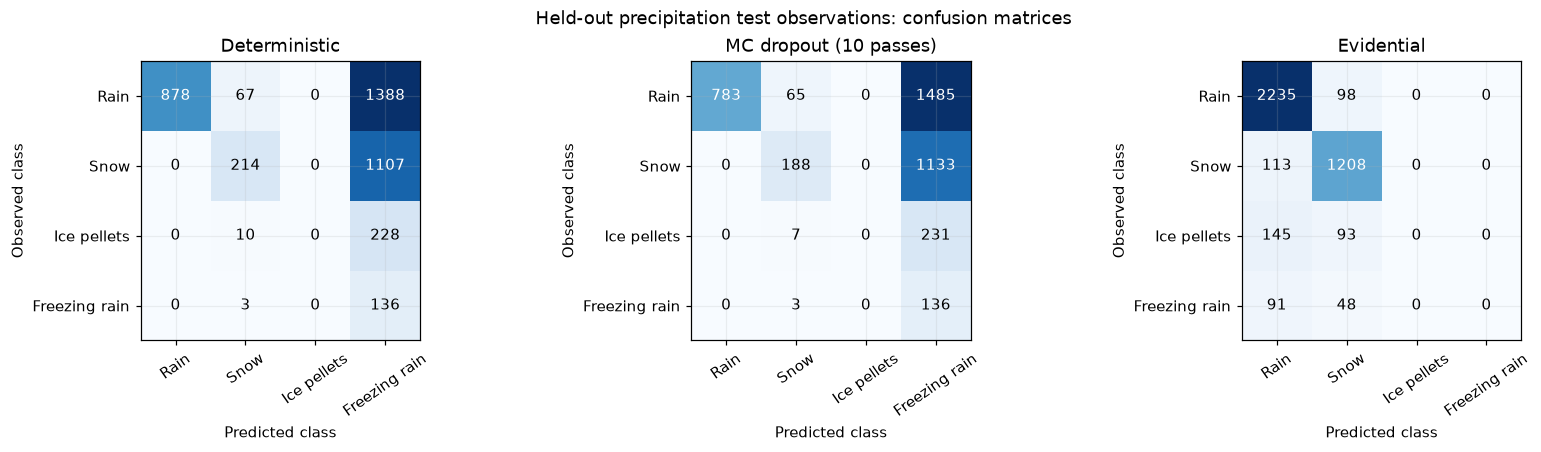

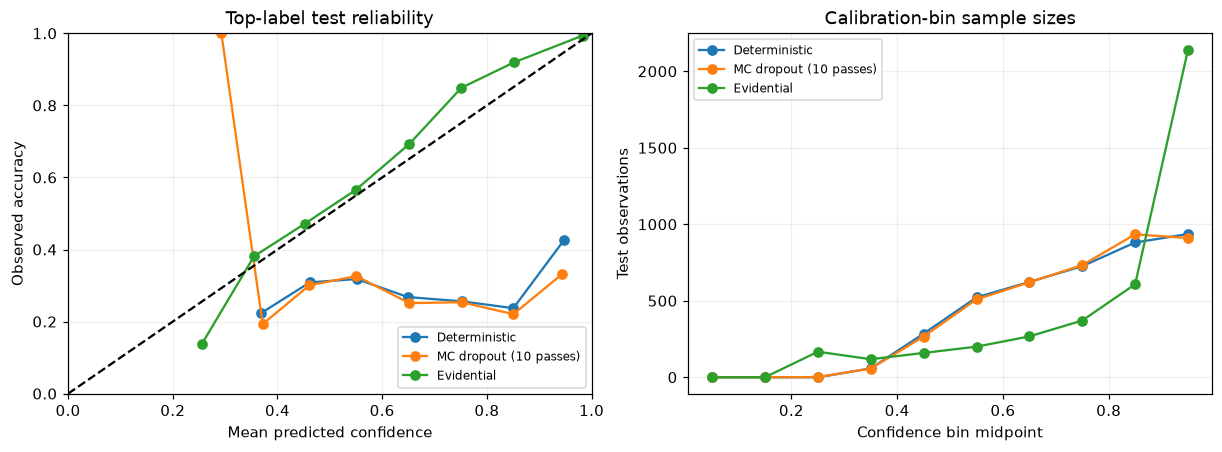

In [4]:
fig,axes = plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for ax,(name,result) in zip(axes,results.items()):
    counts = result["confusion"]
    ax.imshow(counts,cmap="Blues")
    for row in range(len(class_names)):
        for col in range(len(class_names)):
            ax.text(col,row,str(counts[row,col]),ha="center",va="center",
                    color="white" if counts[row,col] > counts.max()/2 else "black")
    ax.set(xticks=range(4),yticks=range(4),xticklabels=class_names,yticklabels=class_names,
           xlabel="Predicted class",ylabel="Observed class",title=name)
    ax.tick_params(axis="x",rotation=35)
fig.suptitle("Held-out precipitation test observations: confusion matrices")
plt.show()
fig,axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for name,result in results.items():
    table = result["reliability"]
    occupied = table["count"] > 0
    axes[0].plot(table.loc[occupied,"confidence"],table.loc[occupied,"accuracy"],"o-",label=name)
    axes[1].plot((table["lower"]+table["upper"])/2,table["count"],"o-",label=name)
    table.to_csv(OUTPUT_DIR/(name.split()[0].lower()+"_test_reliability.csv"),index=False)
axes[0].plot([0,1],[0,1],"k--")
axes[0].set(xlim=(0,1),ylim=(0,1),xlabel="Mean predicted confidence",ylabel="Observed accuracy",title="Top-label test reliability")
axes[1].set(xlabel="Confidence bin midpoint",ylabel="Test observations",title="Calibration-bin sample sizes")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.show()


## Evidential and dropout uncertainty


For each class, the paper's law-of-total-variance decomposition (Eqs. 20–23) is
\[
\underbrace{\mathbb E[\operatorname{Var}(y_{n,k}\mid p_{n,k})]}_{\text{aleatoric}}
=\mathbb E[p_{n,k}(1-p_{n,k})]
=\widehat p_{n,k}(1-\widehat p_{n,k})\frac{S_n}{S_n+1},
\]
\[
\underbrace{\operatorname{Var}(\mathbb E[y_{n,k}\mid p_{n,k}])}_{\text{epistemic}}
=\operatorname{Var}(p_{n,k})
=\frac{\widehat p_{n,k}(1-\widehat p_{n,k})}{S_n+1}.
\]
Their sum is the total class-indicator variance
\[
\operatorname{Var}(y_{n,k})
=\widehat p_{n,k}(1-\widehat p_{n,k}).
\]
The variance traces plotted below sum the corresponding per-class variances over $k$ for each observation $n$; they are not variances across observations. The separate statistic `K / sum(alpha)` is the paper's DST uncertainty mass $u_n=K/S_n$ (Eq. 6), also called **evidential vacuity**. It is not an additive variance component.

The closed-form Dirichlet expressions above apply to the evidential model. For MC dropout, the same law of total variance (Eq. 19) is estimated over repeated dropout predictions. The comparisons below show whether uncertain examples are more often wrong; they do not establish out-of-distribution detection.


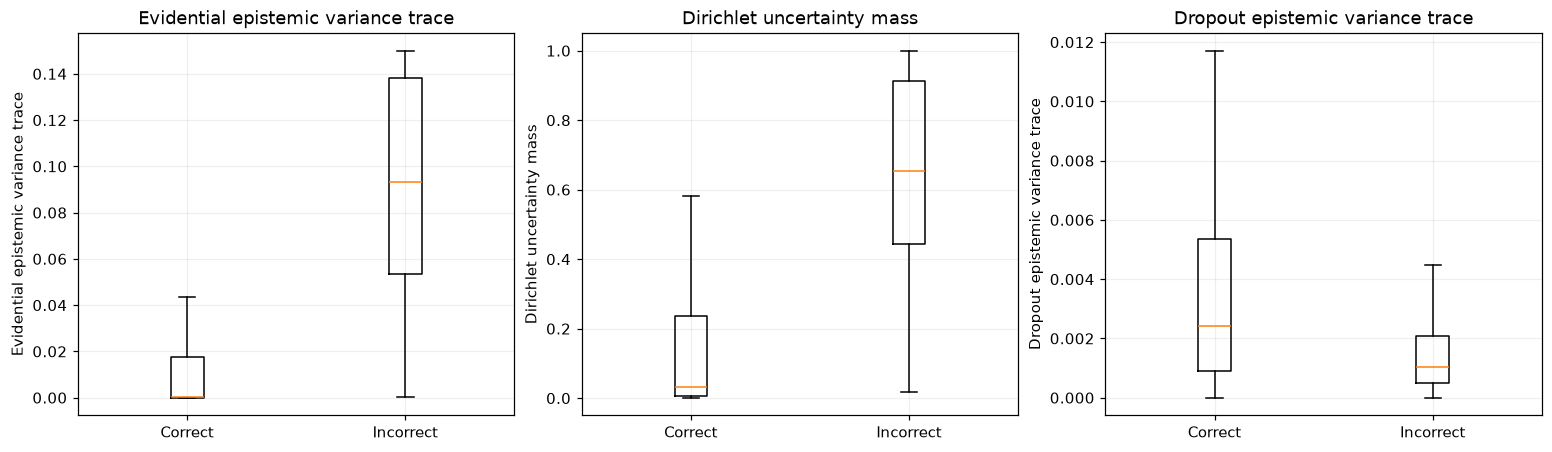

In [5]:
evidential_error = probability.argmax(axis=1) != true_labels
mc_error = mc_probs.argmax(axis=1) != true_labels
fig,axes = plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
for ax,values,error,title in [
    (axes[0],epi.sum(axis=1),evidential_error,"Evidential epistemic variance trace"),
    (axes[1],u.reshape(-1),evidential_error,"Dirichlet uncertainty mass"),
    (axes[2],mc_epi.sum(axis=1),mc_error,"Dropout epistemic variance trace")]:
    groups = [("Correct",values[~error]),("Incorrect",values[error])]
    groups = [(name,value) for name,value in groups if len(value)]
    ax.boxplot([value for _,value in groups],tick_labels=[name for name,_ in groups],showfliers=False)
    ax.set(ylabel=title,title=title)
plt.show()
# Export individual test results with their original source rows/dates.
test_predictions = data["test"][["datetime","day"]].copy()
test_predictions["true_label"] = true_labels
test_predictions["pred_label"] = probability.argmax(axis=1)
test_predictions["dirichlet_uncertainty"] = u.reshape(-1)
for index,name in enumerate(output_features):
    test_predictions[f"probability_{name}"] = probability[:,index]
    test_predictions[f"aleatoric_variance_{name}"] = ale[:,index]
    test_predictions[f"epistemic_variance_{name}"] = epi[:,index]
test_predictions.to_csv(OUTPUT_DIR/"evidential_test_predictions.csv",index_label="source_row")


## Scope of the demonstration

This is the authors' sampled precipitation problem and original short notebook budgets, not a generated benchmark or retuned model. The saved metrics describe this reserved sample test set. For paper experiments, use the intended authors' full dataset and a predeclared validation-based training protocol; keep test observations untouched until final reporting. Weather observations can be temporally or spatially dependent even when days are separated.